In [1]:
import gurobipy as gp
from gurobipy import GRB


import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Input

In [2]:
import json

with open("data/large_instance.json") as f:
    inst = json.load(f)

# Sets
h = inst["horizon"]
H = range(1, h + 1)                              # time horizon {1, ..., h}
Q = inst["qualifications"]                       # qualifications
S = [s["name"] for s in inst["staff"]]           # staff
J = [j["name"] for j in inst["jobs"]]            # projects

# Staff parameters
Q_i = {s["name"]: set(s["qualifications"]) for s in inst["staff"]}   # Q_i ⊆ Q
V_i = {s["name"]: set(s["vacations"]) for s in inst["staff"]}        # V_i ⊆ H

# Project parameters
Q_j = {j["name"]: set(j["working_days_per_qualification"]) for j in inst["jobs"]}   # Q_j' ⊆ Q
n = {(j["name"], k): days
     for j in inst["jobs"]
     for k, days in j["working_days_per_qualification"].items()}     # n[j, k]
g = {j["name"]: j["gain"] for j in inst["jobs"]}                     # gain g_j
d = {j["name"]: j["due_date"] for j in inst["jobs"]}                 # due date d_j
c = {j["name"]: j["daily_penalty"] for j in inst["jobs"]}            # penalty c_j'

In [3]:
n

{('Job1', 'A'): 4,
 ('Job1', 'B'): 4,
 ('Job2', 'A'): 4,
 ('Job2', 'B'): 2,
 ('Job2', 'C'): 1,
 ('Job2', 'D'): 4,
 ('Job3', 'A'): 4,
 ('Job3', 'C'): 1,
 ('Job4', 'A'): 6,
 ('Job6', 'B'): 3,
 ('Job6', 'C'): 4,
 ('Job6', 'D'): 8,
 ('Job7', 'B'): 3,
 ('Job7', 'E'): 4,
 ('Job7', 'H'): 7,
 ('Job8', 'B'): 3,
 ('Job8', 'I'): 4,
 ('Job9', 'C'): 5,
 ('Job9', 'D'): 5,
 ('Job9', 'G'): 8,
 ('Job10', 'C'): 7,
 ('Job10', 'F'): 5,
 ('Job10', 'H'): 8,
 ('Job11', 'C'): 4,
 ('Job11', 'I'): 5,
 ('Job12', 'C'): 8,
 ('Job12', 'J'): 4,
 ('Job13', 'D'): 4,
 ('Job13', 'E'): 5,
 ('Job14', 'D'): 5,
 ('Job14', 'E'): 5,
 ('Job14', 'F'): 1,
 ('Job15', 'D'): 5,
 ('Job15', 'G'): 5,
 ('Job15', 'J'): 3,
 ('Job16', 'D'): 5,
 ('Job16', 'H'): 5,
 ('Job16', 'J'): 2,
 ('Job17', 'E'): 3,
 ('Job17', 'F'): 6,
 ('Job17', 'I'): 8,
 ('Job18', 'E'): 4,
 ('Job18', 'G'): 3,
 ('Job18', 'H'): 2,
 ('Job20', 'F'): 6,
 ('Job21', 'F'): 6,
 ('Job21', 'G'): 2,
 ('Job21', 'H'): 1,
 ('Job22', 'G'): 4,
 ('Job22', 'H'): 4,
 ('Job23', 'G'): 4,


In [4]:
V_i

{'Olivia': {1, 2, 3, 4, 5},
 'Liam': {6, 7, 8, 9, 10},
 'Emma': {21, 22, 23, 24, 25},
 'Noah': {26, 27, 28, 29, 30},
 'Amelia': set(),
 'Oliver': {31, 32, 33}}

In [5]:
Q_j

{'Job1': {'A', 'B'},
 'Job2': {'A', 'B', 'C', 'D'},
 'Job3': {'A', 'C'},
 'Job4': {'A'},
 'Job6': {'B', 'C', 'D'},
 'Job7': {'B', 'E', 'H'},
 'Job8': {'B', 'I'},
 'Job9': {'C', 'D', 'G'},
 'Job10': {'C', 'F', 'H'},
 'Job11': {'C', 'I'},
 'Job12': {'C', 'J'},
 'Job13': {'D', 'E'},
 'Job14': {'D', 'E', 'F'},
 'Job15': {'D', 'G', 'J'},
 'Job16': {'D', 'H', 'J'},
 'Job17': {'E', 'F', 'I'},
 'Job18': {'E', 'G', 'H'},
 'Job20': {'F'},
 'Job21': {'F', 'G', 'H'},
 'Job22': {'G', 'H'},
 'Job23': {'G', 'I', 'J'},
 'Job24': {'G', 'J'},
 'Job25': {'H', 'I'},
 'Job27': {'I', 'J'},
 'Job28': {'J'}}

In [6]:
for k in Q_j["Job1"]:
    print(k)

B
A


In [7]:
for i in n:
    print(i)

('Job1', 'A')
('Job1', 'B')
('Job2', 'A')
('Job2', 'B')
('Job2', 'C')
('Job2', 'D')
('Job3', 'A')
('Job3', 'C')
('Job4', 'A')
('Job6', 'B')
('Job6', 'C')
('Job6', 'D')
('Job7', 'B')
('Job7', 'E')
('Job7', 'H')
('Job8', 'B')
('Job8', 'I')
('Job9', 'C')
('Job9', 'D')
('Job9', 'G')
('Job10', 'C')
('Job10', 'F')
('Job10', 'H')
('Job11', 'C')
('Job11', 'I')
('Job12', 'C')
('Job12', 'J')
('Job13', 'D')
('Job13', 'E')
('Job14', 'D')
('Job14', 'E')
('Job14', 'F')
('Job15', 'D')
('Job15', 'G')
('Job15', 'J')
('Job16', 'D')
('Job16', 'H')
('Job16', 'J')
('Job17', 'E')
('Job17', 'F')
('Job17', 'I')
('Job18', 'E')
('Job18', 'G')
('Job18', 'H')
('Job20', 'F')
('Job21', 'F')
('Job21', 'G')
('Job21', 'H')
('Job22', 'G')
('Job22', 'H')
('Job23', 'G')
('Job23', 'I')
('Job23', 'J')
('Job24', 'G')
('Job24', 'J')
('Job25', 'H')
('Job25', 'I')
('Job27', 'I')
('Job27', 'J')
('Job28', 'J')


In [8]:
g

{'Job1': 15,
 'Job2': 30,
 'Job3': 30,
 'Job4': 30,
 'Job6': 70,
 'Job7': 50,
 'Job8': 50,
 'Job9': 80,
 'Job10': 80,
 'Job11': 20,
 'Job12': 20,
 'Job13': 40,
 'Job14': 20,
 'Job15': 20,
 'Job16': 20,
 'Job17': 80,
 'Job18': 25,
 'Job20': 20,
 'Job21': 25,
 'Job22': 60,
 'Job23': 50,
 'Job24': 50,
 'Job25': 45,
 'Job27': 40,
 'Job28': 50}

In [9]:
d

{'Job1': 26,
 'Job2': 22,
 'Job3': 16,
 'Job4': 18,
 'Job6': 14,
 'Job7': 32,
 'Job8': 18,
 'Job9': 30,
 'Job10': 20,
 'Job11': 32,
 'Job12': 32,
 'Job13': 26,
 'Job14': 30,
 'Job15': 26,
 'Job16': 36,
 'Job17': 18,
 'Job18': 18,
 'Job20': 26,
 'Job21': 18,
 'Job22': 12,
 'Job23': 28,
 'Job24': 26,
 'Job25': 12,
 'Job27': 14,
 'Job28': 14}

In [10]:
c

{'Job1': 3,
 'Job2': 3,
 'Job3': 3,
 'Job4': 3,
 'Job6': 3,
 'Job7': 3,
 'Job8': 3,
 'Job9': 3,
 'Job10': 3,
 'Job11': 3,
 'Job12': 3,
 'Job13': 3,
 'Job14': 3,
 'Job15': 3,
 'Job16': 3,
 'Job17': 3,
 'Job18': 3,
 'Job20': 3,
 'Job21': 3,
 'Job22': 3,
 'Job23': 3,
 'Job24': 3,
 'Job25': 3,
 'Job27': 3,
 'Job28': 3}

# Model

In [11]:
# Create initial model.
m = gp.Model("staff")

Set parameter Username
Set parameter LicenseID to value 2885186
Academic license - for non-commercial use only - expires 2027-11-16


# Variables

In [12]:
# Initialize assignment decision variables.

# x[i,t,j,k]: only valid combinations (qualified, not on vacation, project needs k)
idx = [(i, t, j, k)
       for i in S
       for t in H if t not in V_i[i]
       for j in J
       for k in Q_j[j] & Q_i[i]]

idx

[('Olivia', 6, 'Job1', 'B'),
 ('Olivia', 6, 'Job1', 'A'),
 ('Olivia', 6, 'Job2', 'B'),
 ('Olivia', 6, 'Job2', 'A'),
 ('Olivia', 6, 'Job2', 'C'),
 ('Olivia', 6, 'Job3', 'A'),
 ('Olivia', 6, 'Job3', 'C'),
 ('Olivia', 6, 'Job4', 'A'),
 ('Olivia', 6, 'Job6', 'B'),
 ('Olivia', 6, 'Job6', 'C'),
 ('Olivia', 6, 'Job7', 'B'),
 ('Olivia', 6, 'Job8', 'B'),
 ('Olivia', 6, 'Job9', 'C'),
 ('Olivia', 6, 'Job10', 'C'),
 ('Olivia', 6, 'Job11', 'C'),
 ('Olivia', 6, 'Job12', 'C'),
 ('Olivia', 7, 'Job1', 'B'),
 ('Olivia', 7, 'Job1', 'A'),
 ('Olivia', 7, 'Job2', 'B'),
 ('Olivia', 7, 'Job2', 'A'),
 ('Olivia', 7, 'Job2', 'C'),
 ('Olivia', 7, 'Job3', 'A'),
 ('Olivia', 7, 'Job3', 'C'),
 ('Olivia', 7, 'Job4', 'A'),
 ('Olivia', 7, 'Job6', 'B'),
 ('Olivia', 7, 'Job6', 'C'),
 ('Olivia', 7, 'Job7', 'B'),
 ('Olivia', 7, 'Job8', 'B'),
 ('Olivia', 7, 'Job9', 'C'),
 ('Olivia', 7, 'Job10', 'C'),
 ('Olivia', 7, 'Job11', 'C'),
 ('Olivia', 7, 'Job12', 'C'),
 ('Olivia', 8, 'Job1', 'B'),
 ('Olivia', 8, 'Job1', 'A'),
 ('Olivi

In [13]:
# matrix of peapole, job, skill, day
x = m.addVars(idx, vtype=GRB.BINARY, name="x")

# auxilliary variable: project j completed in horizon
y = m.addVars(J, vtype=GRB.BINARY, name='y')

# completion day of the project
e = m.addVars(J, vtype=GRB.INTEGER, lb=0, ub=h, name='e')

# number of days late of the project
l = m.addVars(J, vtype=GRB.INTEGER, lb=0, name='l')

In [ ]:
# --- auxiliary variables (used to express the objectives) ---

# last_day: last completion day over all projects (makespan)
last_day = m.addVar(vtype=GRB.INTEGER, lb=0, ub=h, name="last_day")

# z[i,j] = 1 if employee i works at least one day on project j
z = m.addVars(S, J, vtype=GRB.BINARY, name="project_worked")

# P: max number of projects worked on by any single employee
P = m.addVar(vtype=GRB.INTEGER, lb=0, ub=len(J), name="max_projects")

# r[j] = 1 if project j is delivered late, 0 otherwise
r = m.addVars(J, vtype=GRB.BINARY, name="late")

# Constraints

In [14]:
# one staff member works on at most one project (and one skill) per day
daily_assignment = m.addConstrs(
    (x.sum(i, t, "*", "*") <= 1 for i in S for t in H if t not in V_i[i]),
    name="daily_assignment",
)
daily_assignment

{('Olivia', 6): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 7): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 8): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 9): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 10): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 11): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 12): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 13): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 14): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 15): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 16): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 17): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 18): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 19): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 20): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 21): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 22): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 23): <

In [15]:
# a project is either fully covered for each qualification (y=1) or not worked on at all (y=0)
completed_project = m.addConstrs((x.sum("*", "*", j, k) == n[j,k] * y[j] for j in J for k in Q_j[j]), name="coverage",)
completed_project

{('Job1', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job1', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job2', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job2', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job2', 'D'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job2', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job3', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job3', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job4', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job6', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job6', 'D'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job6', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job7', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job7', 'E'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job7', 'H'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job8', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job8', 'I'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job9', 'G'): <gurobi.Constr 

In [16]:
# the completion day is at least every day someone works on the project
end_day = m.addConstrs((e[j] >= t * x[i, t, j, k] for (i, t, j, k) in idx), name="end_day")
end_day

{('Olivia', 6, 'Job1', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job1', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job2', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job2', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job2', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job3', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job3', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job4', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job6', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job6', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job7', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job8', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job9', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job10', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 6, 'Job

In [17]:
# days late = completion day - due date (0 if on time)
lateness = m.addConstrs((l[j] >= e[j] - d[j] for j in J), name="lateness")
lateness

{'Job1': <gurobi.Constr *Awaiting Model Update*>,
 'Job2': <gurobi.Constr *Awaiting Model Update*>,
 'Job3': <gurobi.Constr *Awaiting Model Update*>,
 'Job4': <gurobi.Constr *Awaiting Model Update*>,
 'Job6': <gurobi.Constr *Awaiting Model Update*>,
 'Job7': <gurobi.Constr *Awaiting Model Update*>,
 'Job8': <gurobi.Constr *Awaiting Model Update*>,
 'Job9': <gurobi.Constr *Awaiting Model Update*>,
 'Job10': <gurobi.Constr *Awaiting Model Update*>,
 'Job11': <gurobi.Constr *Awaiting Model Update*>,
 'Job12': <gurobi.Constr *Awaiting Model Update*>,
 'Job13': <gurobi.Constr *Awaiting Model Update*>,
 'Job14': <gurobi.Constr *Awaiting Model Update*>,
 'Job15': <gurobi.Constr *Awaiting Model Update*>,
 'Job16': <gurobi.Constr *Awaiting Model Update*>,
 'Job17': <gurobi.Constr *Awaiting Model Update*>,
 'Job18': <gurobi.Constr *Awaiting Model Update*>,
 'Job20': <gurobi.Constr *Awaiting Model Update*>,
 'Job21': <gurobi.Constr *Awaiting Model Update*>,
 'Job22': <gurobi.Constr *Awaiting Mode

In [ ]:
# --- auxiliary constraints (link the auxiliary variables to x, e and l) ---

# last_day = max of the completion days
makespan = m.addConstr(last_day == gp.max_(list(e.values())), name="makespan")

# z[i,j] = OR of all x[i,t,j,k]: 1 as soon as employee i works one day on project j
project_worked = {
    (i, j): m.addGenConstrOr(
        z[i, j],
        [x[i, t, j, k] for t in H for k in Q if (i, t, j, k) in x],
        name=f"project_worked[{i},{j}]",
    )
    for i in S for j in J
}

# P is at least the number of projects of each employee
max_projects = m.addConstrs((P >= z.sum(i, "*") for i in S), name="max_projects")

# r[j] = 0 -> no delay ; r[j] = 1 -> at least one day late (l is integer)
late_off = m.addConstrs(((r[j] == 0) >> (l[j] == 0) for j in J), name="late_off")
late_on  = m.addConstrs(((r[j] == 1) >> (l[j] >= 1) for j in J), name="late_on")

# Objective functions

In [ ]:
# Project brief specifies:
# 1) Maximize total profit realized
# 2) Minimize the actual project execution time
# 3) Minimize the number of projects an employee works on
# 4) Minimize the number of projects delivered late
# The auxiliary variables/constraints are defined above: these functions only return an expression.

def objective_profit(y, g, c, l):
    # gain of completed projects - late penalty * days late
    return gp.quicksum(g[j] * y[j] - c[j] * l[j] for j in J)

def objective_execution_time(last_day):
    # last completion day over all projects
    return last_day

def objective_projects_per_employee(P):
    # max number of projects worked on by any employee
    return P

def objective_projects_late(r):
    # number of projects delivered late
    return r.sum()

In [ ]:
# build the 4 objectives
profit = objective_profit(y, g, c, l)
execution_time = objective_execution_time(last_day)
projects_per_employee = objective_projects_per_employee(P)
projects_late = objective_projects_late(r)

In [20]:
# lexicographic (hierarchical) optimization, in the order of the brief:
# the higher the priority, the earlier the objective is optimized.
# ModelSense is MAXIMIZE, so the objectives to minimize get weight = -1
m.ModelSense = GRB.MAXIMIZE

m.setObjectiveN(profit,                index=0, priority=4, weight=1,  name="profit")
m.setObjectiveN(execution_time,        index=1, priority=3, weight=-1, name="execution_time")
m.setObjectiveN(projects_per_employee, index=2, priority=2, weight=-1, name="projects_per_employee")
m.setObjectiveN(projects_late,         index=3, priority=1, weight=-1, name="projects_late")

# Solve

In [21]:
m.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 27.0.0 26A434)

CPU model: Apple M5 Pro
Thread count: 18 physical cores, 18 logical processors, using up to 18 threads

Optimize a model with 4223 rows, 4191 columns and 16022 nonzeros (Max)
Model fingerprint: 0x29bb0a55
Model has 50 linear objective coefficients
Model has 201 simple general constraints
  1 MAX, 150 OR, 50 INDICATOR
Variable types: 2 continuous, 4189 integer (4139 binary)
Coefficient statistics:
  Matrix range     [1e+00, 4e+01]
  Objective range  [1e+00, 8e+01]
  Bounds range     [1e+00, 4e+01]
  RHS range        [1e+00, 4e+01]
  GenCon rhs range [1e+00, 1e+00]
  GenCon coe range [1e+00, 1e+00]


---------------------------------------------------------------------------
Multi-objectives: starting optimization (max) with 4 objectives... 
---------------------------------------------------------------------------

Multi-objectives: applying initial presolve...
----------------------------------------

# Results

In [22]:
# value of each objective
for o in range(m.NumObj):
    m.Params.ObjNumber = o
    print(f"{m.ObjNName}: {m.ObjNVal:g}")

profit: 817
execution_time: 36
projects_per_employee: 7.0007
projects_late: 2


In [23]:
# schedule: staff x days
schedule = pd.DataFrame("", index=S, columns=list(H))
for i in S:
    for t in V_i[i]:
        schedule.loc[i, t] = "vacation"
for (i, t, j, k), var in x.items():
    if var.X > 0.5:
        schedule.loc[i, t] = f"{j} ({k})"

schedule

,1,2,3,4,5,6,7,8,9,10,...,27,28,29,30,31,32,33,34,35,36
Olivia,vacation,vacation,vacation,vacation,vacation,Job6 (C),Job6 (B),Job6 (C),Job3 (A),Job3 (C),...,Job7 (B),Job7 (B),Job7 (B),Job9 (C),Job11 (C),Job11 (C),Job9 (C),Job9 (C),Job9 (C),
Liam,Job4 (A),Job4 (A),Job6 (D),Job6 (D),Job4 (A),vacation,vacation,vacation,vacation,vacation,...,Job9 (D),Job7 (E),Job7 (E),Job7 (E),Job7 (E),Job16 (D),Job9 (D),Job9 (D),Job16 (D),Job16 (D)
Emma,Job25 (H),Job10 (H),Job25 (H),Job22 (H),Job25 (H),Job8 (B),Job10 (H),Job25 (H),Job25 (H),Job25 (H),...,Job7 (H),Job7 (H),Job7 (H),Job7 (H),Job7 (H),Job7 (H),Job16 (H),Job16 (H),Job16 (H),Job16 (H)
Noah,Job6 (D),Job6 (D),Job6 (D),Job6 (D),Job10 (H),Job6 (D),Job6 (C),Job22 (G),Job22 (G),Job22 (G),...,vacation,vacation,vacation,vacation,Job9 (G),Job9 (D),Job16 (H),Job9 (D),Job16 (D),Job16 (D)
Amelia,Job17 (I),Job8 (I),Job8 (I),Job17 (F),Job17 (F),Job25 (I),Job8 (I),Job8 (I),Job17 (I),Job25 (I),...,Job11 (I),Job23 (I),Job11 (I),Job11 (I),Job11 (I),Job11 (I),Job9 (G),Job9 (G),Job9 (G),Job16 (J)
Oliver,Job28 (J),Job28 (J),Job10 (F),Job28 (J),Job28 (J),Job10 (F),Job28 (J),Job28 (J),Job17 (F),Job28 (J),...,Job23 (J),Job23 (J),Job9 (G),Job9 (G),vacation,vacation,vacation,Job9 (G),Job9 (G),Job16 (J)


In [24]:
# projects: completed or not, completion day and delay
projects = pd.DataFrame({
    "completed": {j: int(round(y[j].X)) for j in J},
    "end_day":   {j: int(round(e[j].X)) if y[j].X > 0.5 else None for j in J},
    "due_date":  d,
    "days_late": {j: int(round(l[j].X)) for j in J},
    "gain":      g,
})

projects

,completed,end_day,due_date,days_late,gain
Job1,0,NaN,26,0,15
Job2,1,23.0,22,1,30
Job3,1,16.0,16,0,30
Job4,1,18.0,18,0,30
Job6,1,14.0,14,0,70
Job7,1,32.0,32,0,50
Job8,1,18.0,18,0,50
Job9,1,35.0,30,5,80
Job10,1,20.0,20,0,80
Job11,1,32.0,32,0,20


In [25]:
# objectifs : profit d'abord, puis durée pour départager les égalités
m.setObjectiveN(profit,                0, priority=2, weight=1,  name="profit")
m.setObjectiveN(execution_time,        1, priority=1, weight=-1, name="execution_time")
m.setObjectiveN(projects_per_employee, 2, priority=0, weight=0)   # désactivé
m.setObjectiveN(projects_late,         3, priority=0, weight=0)   # désactivé
m.Params.OutputFlag = 0

eps_constr = m.addConstr(execution_time <= h, name="eps")
pareto = []
eps = h
while eps >= 0:
    eps_constr.RHS = eps
    m.optimize()
    if m.Status != GRB.OPTIMAL:
        break
    t = round(execution_time.X)
    pareto.append((profit.getValue(), t))
    eps = t - 1

m.remove(eps_constr)
m.Params.OutputFlag = 1
pareto


Set parameter OutputFlag to value 1


[(817.0, 36),
 (808.0, 35),
 (797.0, 34),
 (794.0, 33),
 (782.0, 32),
 (765.0, 31),
 (759.0, 30),
 (737.0, 29),
 (715.0, 28),
 (695.0, 27),
 (685.0, 26),
 (665.0, 25),
 (645.0, 24),
 (625.0, 23),
 (605.0, 22),
 (585.0, 21),
 (555.0, 20),
 (535.0, 19),
 (505.0, 18),
 (475.0, 17),
 (465.0, 16),
 (435.0, 15),
 (405.0, 14),
 (385.0, 13),
 (355.0, 12),
 (325.0, 11),
 (285.0, 10),
 (260.0, 9),
 (235.0, 8),
 (200.0, 7),
 (190.0, 6),
 (150.0, 5),
 (140.0, 4),
 (60.0, 2),
 (0.0, 0)]

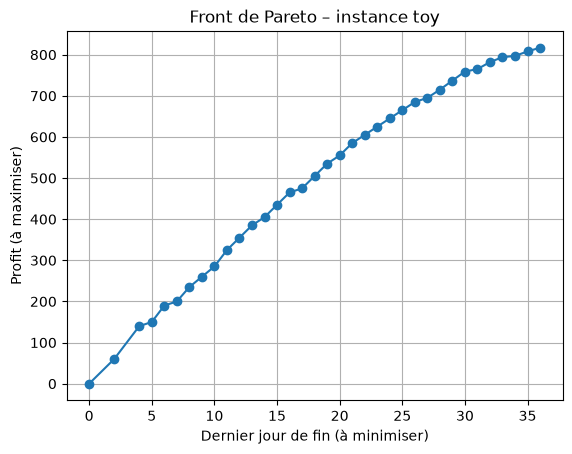

In [26]:
times   = [t for p, t in pareto]
profits = [p for p, t in pareto]

plt.plot(times, profits, "o-")
plt.xlabel("Dernier jour de fin (à minimiser)")
plt.ylabel("Profit (à maximiser)")
plt.title("Front de Pareto – instance toy")
plt.grid(True)
plt.show()
